# 🏅 Olympics Analytics Platform — Google Colab runner

Runs the **whole project** (data quality → statistics → SQL → forecasting → 14-model comparison → calibrated medal model → monitoring → report) and saves **everything to your Google Drive**.

**Disconnect-safe:** every stage and every model is checkpointed in Drive. If the runtime dies, just open the notebook and choose *Runtime → Run all* — finished stages are skipped and the run continues where it stopped.

**Before you start (one time)**
1. Put `olympics-analytics-platform.zip` in your Google Drive, in a folder called `Olympics-Analytics` (or upload it when cell 3 asks).
2. Create a free Kaggle API token (kaggle.com → Settings → API) and add it to Colab **Secrets** (🔑 icon on the left): `KAGGLE_USERNAME` and `KAGGLE_KEY` (or the new single `KAGGLE_API_TOKEN`). Open each dataset page once on kaggle.com and accept its terms.
3. No Kaggle yet? Tick `USE_DEMO_DATA` below to run everything on built-in synthetic data.

**Where things end up** (inside `MyDrive/Olympics-Analytics/`)

| Folder | Content |
|---|---|
| `project/` | the code |
| `workspace/data/` | raw download, cleaned data (parquet) |
| `workspace/reports/figures/` | all charts (PNG) + `FIGURES.md` captions |
| `workspace/reports/tables/` | every table as CSV (model comparison, tests, forecasts, drift…) |
| `workspace/reports/metrics/` | all metrics as JSON, `REPORT.html` is in `workspace/reports/` |
| `workspace/models/` | versioned models + model cards |
| `workspace/mlruns/`, `checkpoints/`, `feedback/`, `logs/` | experiment tracking, resume state, human feedback, logs |

## 1 · Settings

In [1]:
#@title Settings { display-mode: "form" }
DRIVE_FOLDER   = "Olympics-Analytics"   #@param {type:"string"}
DATA_SOURCE    = "heesoo37_120y"         #@param ["heesoo37_120y", "olympedia"]
PROFILE        = "full"                  #@param ["fast", "full"]
USE_DEMO_DATA  = False                   #@param {type:"boolean"}
FORCE_STAGES   = ""                      #@param {type:"string"}
# FORCE_STAGES: space separated stages to recompute, e.g. "compare final"  (or "all"). Leave empty to resume.

## 2 · Mount Google Drive

In [2]:
import os, sys, shutil, zipfile, subprocess, importlib, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    BASE = Path("/content/drive/MyDrive") / DRIVE_FOLDER
except ImportError:                       # running locally (for testing)
    IN_COLAB = False
    BASE = Path.home() / DRIVE_FOLDER

BASE.mkdir(parents=True, exist_ok=True)
PROJECT = BASE / "project"
ROOT = BASE / "workspace"                 # every output goes here
print("Drive folder :", BASE)
print("Outputs      :", ROOT)

Mounted at /content/drive
Drive folder : /content/drive/MyDrive/Olympics-Analytics
Outputs      : /content/drive/MyDrive/Olympics-Analytics/workspace


## 3 · Get the code (first run only — kept in your Drive afterwards)

In [3]:
def _find_zip():
    names = ["olympics-analytics-platform.zip"]
    for folder in (BASE, Path("/content"), Path("/content/drive/MyDrive"), Path.cwd()):
        for n in names:
            if (folder / n).exists():
                return folder / n
    return None

if not (PROJECT / "src" / "olympics").exists():
    z = _find_zip()
    if z is None and IN_COLAB:
        from google.colab import files
        print("Upload olympics-analytics-platform.zip ...")
        up = files.upload()
        z = Path("/content") / next(iter(up))
    assert z is not None, "Put olympics-analytics-platform.zip into the Drive folder and re-run this cell."
    tmp = Path("/tmp/_olympics_unzip"); shutil.rmtree(tmp, ignore_errors=True)
    with zipfile.ZipFile(z) as zf: zf.extractall(tmp)
    inner = next(p for p in tmp.rglob("params.yaml")).parent
    PROJECT.mkdir(parents=True, exist_ok=True)
    shutil.copytree(inner, PROJECT, dirs_exist_ok=True)
    print("Code installed to", PROJECT)
else:
    print("Code already in Drive:", PROJECT)

sys.path[:0] = [str(PROJECT / "src"), str(PROJECT)]
os.environ["PYTHONPATH"] = f"{PROJECT / 'src'}:{PROJECT}"
os.environ["OLYMPICS_ROOT"] = str(ROOT)
os.chdir(PROJECT)

Upload olympics-analytics-platform.zip ...


Saving olympics-analytics-platform.zip to olympics-analytics-platform.zip
Code installed to /content/drive/MyDrive/Olympics-Analytics/project


## 4 · Install dependencies (≈2–3 min per fresh Colab session)

In [4]:
need = {"statsmodels": "statsmodels", "xgboost": "xgboost", "lightgbm": "lightgbm", "catboost": "catboost", "shap": "shap",
        "mlflow": "mlflow", "evidently": "evidently", "kaggle": "kaggle", "pyarrow": "pyarrow", "tabulate": "tabulate",
        "markdown": "markdown", "gradio": "gradio", "fastapi": "fastapi", "uvicorn": "uvicorn", "plotly": "plotly", "httpx": "httpx"}
missing = [pkg for mod, pkg in need.items() if importlib.util.find_spec(mod) is None]
if missing and IN_COLAB:
    print("Installing:", ", ".join(missing))
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], capture_output=True, text=True)
    print(r.stdout[-500:], r.stderr[-800:] if r.returncode else "")
    importlib.invalidate_caches()
elif missing:
    print("Not installed (optional, skipped locally):", missing)
else:
    print("All dependencies present.")
import sklearn, pandas
print("pandas", pandas.__version__, "| scikit-learn", sklearn.__version__)

Installing: catboost, mlflow, evidently
 
pandas 2.2.3 | scikit-learn 1.6.1


## 5 · Kaggle credentials

In [5]:
if USE_DEMO_DATA:
    print("Demo mode: synthetic data, no Kaggle needed.")
else:
    def _secret(name):
        try:
            from google.colab import userdata
            return userdata.get(name)
        except Exception:
            return os.environ.get(name)
    user, key, token = _secret("KAGGLE_USERNAME"), _secret("KAGGLE_KEY"), _secret("KAGGLE_API_TOKEN")
    if token:
        os.environ["KAGGLE_API_TOKEN"] = token
    if user and key:
        os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = user, key
    have_file = (Path.home() / ".kaggle" / "kaggle.json").exists()
    if not (token or (user and key) or have_file):
        if IN_COLAB:
            from google.colab import files
            print("No Kaggle secret found. Upload your kaggle.json:")
            up = files.upload()
            (Path.home() / ".kaggle").mkdir(exist_ok=True)
            shutil.move(next(iter(up)), Path.home() / ".kaggle" / "kaggle.json")
            os.chmod(Path.home() / ".kaggle" / "kaggle.json", 0o600)
        else:
            print("No Kaggle credentials found (fine if data.local_dir is set).")
    print("Kaggle credentials ready.")

No Kaggle secret found. Upload your kaggle.json:


Saving kaggle.json to kaggle.json
Kaggle credentials ready.


## 6 · Create the pipeline

In [8]:
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Your original code follows...
from olympics.config import load_config
from olympics.pipeline import Pipeline, STAGES


In [9]:
from olympics.config import load_config
from olympics.pipeline import Pipeline, STAGES

overrides = [f"data.source={DATA_SOURCE}", f"ml.profile={PROFILE}"]
cfg = load_config(overrides=overrides)
pipe = Pipeline(cfg, ROOT, demo=USE_DEMO_DATA)
FORCE = FORCE_STAGES.split()
print("Stages:", STAGES)
print("Already finished:", list(pipe.ck.status()) or "none")

def stage(*names, **kw):
    """Run stages (checkpoint-aware). Safe to re-run after a disconnect."""
    out = pipe.run(list(names), FORCE, **kw)
    return out

2026/11/02 04:20:46 INFO mlflow.tracking.fluent: Experiment with name 'olympics-medal-model' does not exist. Creating a new experiment.


Stages: ['ingest', 'clean', 'sql', 'stats', 'forecast', 'features', 'compare', 'final', 'monitor', 'report']
Already finished: none


## 7 · Run the pipeline
Each cell can be run on its own and is safe to re-run.

### 7a · Download → validate → clean → SQL layer

In [10]:
r = stage("ingest", "clean", "sql", force_download=False)
print(r)
from IPython.display import Markdown, display
display(Markdown((pipe.paths.tables / "data_quality_report.md").read_text()))

04:20:50 | INFO | [stage] ingest       starting
INFO:olympics:[stage] ingest       starting


Dataset URL: https://www.kaggle.com/datasets/heesoo37/120-years-of-olympic-history-athletes-and-results


100%|██████████| 5.43M/5.43M [00:00<00:00, 7.47MB/s]


04:20:53 | INFO | Loaded heesoo37_120y: 271116 rows, 15 columns
INFO:olympics:Loaded heesoo37_120y: 271116 rows, 15 columns
04:20:54 | INFO | [stage] ingest       finished in 4.2s
INFO:olympics:[stage] ingest       finished in 4.2s
04:20:54 | INFO | [stage] clean        starting
INFO:olympics:[stage] clean        starting
04:21:22 | INFO | [stage] clean        finished in 28.7s
INFO:olympics:[stage] clean        finished in 28.7s
04:21:22 | INFO | [stage] sql          starting
INFO:olympics:[stage] sql          starting
04:21:29 | INFO | [stage] sql          finished in 6.5s
INFO:olympics:[stage] sql          finished in 6.5s


{'ingest': {'rows': 271116, 'source': 'heesoo37_120y'}, 'clean': {'rows_out': 267998, 'quality_score': 86, 'exact_duplicates_removed': 1385}, 'sql': {'queries_exported': 6, 'available_queries': ['athlete_career', 'country_medal_summary', 'country_trend', 'event_medals', 'host_effect', 'medal_rank_by_games', 'participation_trend', 'sport_profile']}}


# Data quality report

**Quality score: 86/100** — 271,116 rows, 15 columns — 0 critical, 7 warnings, 5 info, 19 passed

| | Check | Count | % rows | Examples | Note |
|---|---|---:|---:|---|---|
| ✅ | Required columns present | 0 | 0.0 |  | All of: ID, Sex, Age, NOC, Games, Year, Season, Sport, Event, Medal |
| 🔵 | Missing Age | 9,474 | 3.4944 |  | Handled by median imputation + missing-indicator in the model pipeline. |
| 🟠 | Missing Height | 60,171 | 22.1938 |  | Handled by median imputation + missing-indicator in the model pipeline. |
| 🟠 | Missing Weight | 62,875 | 23.1912 |  | Handled by median imputation + missing-indicator in the model pipeline. |
| ✅ | Missing ID (key field) | 0 | 0.0 |  |  |
| ✅ | Missing NOC (key field) | 0 | 0.0 |  |  |
| ✅ | Missing Year (key field) | 0 | 0.0 |  |  |
| ✅ | Missing Sport (key field) | 0 | 0.0 |  |  |
| ✅ | Missing Event (key field) | 0 | 0.0 |  |  |
| 🟠 | Exact duplicate rows | 1,385 | 0.5109 |  | Removed during cleaning. |
| 🟠 | Same athlete listed twice for the same Games+Event | 95 | 0.035 |  | Usually data-entry repeats; kept after full-row dedup so counts stay conservative. |
| ✅ | Age outside [10, 100] | 0 | 0.0 |  |  |
| ✅ | Height outside [120, 240] cm | 0 | 0.0 |  |  |
| ✅ | Weight outside [25, 250] kg | 0 | 0.0 |  |  |
| 🟠 | Implied BMI outside [10, 60] | 3 | 0.0011 |  |  |
| ✅ | Sex not coded as M/F (after trimming) | 0 | 0.0 |  |  |
| ✅ | Sex with stray whitespace/lowercase | 0 | 0.0 |  |  |
| ✅ | Medal value outside Gold/Silver/Bronze | 0 | 0.0 |  |  |
| ✅ | Season not Summer/Winter | 0 | 0.0 |  |  |
| ✅ | Games label disagrees with Year/Season | 0 | 0.0 |  |  |
| 🟠 | NOC codes absent from the regions lookup | 349 | 0.1287 | SGP | Rows keep the NOC code as their country label. |
| 🔵 | Known typos in region names | 1 | 0.0004 | Boliva -> Bolivia |  |
| 🔵 | Regions covered by several NOC codes (historic / merged states) | 14 | 0.0052 | Australia: 2 codes, Canada: 2 codes, China: 2 codes, Czech Republic: 3 codes, Germany: 4 codes | e.g. West/East Germany (FRG, GDR, GER) -> Germany. Region-level tallies merge them; NOC-level keeps them apart. |
| 🔵 | Team name differs from region of its NOC | 57,285 | 21.1293 | Denmark/Sweden, United States, Taifun, Soviet Union, United Arab Republic | Expected for mixed teams, boycotts and renamed countries. |
| ✅ | Team values that differ only by case/whitespace | 0 | 0.0 |  |  |
| ✅ | Sport values that differ only by case/whitespace | 0 | 0.0 |  |  |
| ✅ | Event values that differ only by case/whitespace | 0 | 0.0 |  |  |
| ✅ | Athlete IDs recorded with more than one Sex | 0 | 0.0 |  |  |
| ✅ | Athlete IDs with implied birth year spread > 2 | 0 | 0.0 |  | Indicates reused IDs or wrong ages (the same athlete cannot be two different ages). |
| 🔵 | Editions with unusually few athletes (<10% of median) | 1 | 0.0004 | 1896 Summer: 176 |  |
| 🟠 | Events with gold medals for >2 different NOCs | 3 | 0.0011 | 1900 Summer / Rugby Men's Rugby, 1924 Winter / Alpinism Mixed Alpinism, 1988 Summer / Gymnastics Men's Pommelled Horse | Possible mis-keyed event names. |


### 7b · Statistics, hypothesis tests and figures

In [11]:
r = stage("stats"); print(r)
import pandas as pd
display(pd.read_csv(pipe.paths.tables / "medalist_vs_rest_tests.csv").round(3))

04:21:29 | INFO | [stage] stats        starting
INFO:olympics:[stage] stats        starting
04:21:39 | INFO | [stage] stats        finished in 9.8s
INFO:olympics:[stage] stats        finished in 9.8s


{'stats': {'trend_athletes': 'increasing', 'age_kruskal_p': 0.0, 'participation_spearman': 0.7823282050436705, 'host_uplift_pp': 7.817002657511222}}


,variable,group_a,group_b,n_a,n_b,mean_a,mean_b,mean_diff,diff_ci_low,diff_ci_high,welch_t,welch_p,mannwhitney_p,cohens_d,effect_magnitude,interpretation,welch_p_holm
0,Age,medallists,non-medallists,38737,220689,25.915,25.366,0.549,0.485,0.613,16.772,0.0,0.0,0.089,negligible,medallists vs non-medallists: mean Age differs...,0.0
1,Height,medallists,non-medallists,30992,179665,177.552,174.953,2.599,2.468,2.729,39.012,0.0,0.0,0.248,small,medallists vs non-medallists: mean Height diff...,0.0
2,Weight,medallists,non-medallists,30386,177610,73.762,70.171,3.591,3.409,3.772,38.826,0.0,0.0,0.251,small,medallists vs non-medallists: mean Weight diff...,0.0
3,BMI,medallists,non-medallists,30127,176508,23.162,22.719,0.443,0.407,0.479,24.126,0.0,0.0,0.153,negligible,medallists vs non-medallists: mean BMI differs...,0.0


### 7c · Medal forecasting (rolling-origin backtest)

In [12]:
r = stage("forecast"); print(r)
display(pd.read_csv(pipe.paths.tables / "forecast_model_comparison.csv"))
display(pd.read_csv(pipe.paths.tables / "forecast_next_edition.csv").head(10).round(1))

04:21:39 | INFO | [stage] forecast     starting
INFO:olympics:[stage] forecast     starting
04:21:54 | INFO | [stage] forecast     finished in 15.0s
INFO:olympics:[stage] forecast     finished in 15.0s


{'forecast': {'best_model': 'naive_last', 'best_mae': 6.2533}}


,model,mae,rmse,smape,rel_mae_vs_naive,bias,spearman,poisson_deviance,mae_std_across_editions,editions
0,naive_last,6.2533,8.9111,27.9112,1.0000,-0.3067,0.8835,12.3934,1.7681,6
1,ewma,7.1390,10.1066,31.7513,1.1435,-1.3742,0.8602,13.0799,2.0974,6
2,mean_last3,7.6889,10.5551,34.9201,1.2416,-1.2844,0.8362,13.5823,2.1897,6
3,arima_1_0_0,7.7669,11.2488,37.7677,1.2815,-5.1216,0.8423,17.3506,1.3332,6
4,ensemble_mean,7.9396,11.9323,31.1151,1.3063,-2.5590,0.8637,4.7206,2.0793,6
5,random_forest_lag,7.9875,11.3484,32.3591,1.3343,-0.3972,0.8390,4.8994,1.2593,6
6,poisson_glm,8.2699,13.4509,30.4008,1.3291,-1.0822,0.8517,4.5550,3.4626,6
7,hist_gbm_poisson,8.5121,12.9061,32.2956,1.4269,-1.8483,0.8551,5.3559,1.6264,6
8,theil_sen_trend,9.3662,13.4964,41.9798,1.5798,-0.5341,0.8180,24.6644,0.9776,6
9,ets_damped,10.2880,15.7799,40.1796,1.6932,1.3404,0.7761,16.0437,1.7551,6


,country,edition,forecast,lower,upper,last_actual,host,model
0,USA,2020,121.0,100.3,156.9,121.0,0,naive_last
1,China,2020,70.0,54.2,97.4,70.0,0,naive_last
2,UK,2020,67.0,51.5,93.8,67.0,0,naive_last
3,Russia,2020,56.0,41.8,80.5,56.0,0,naive_last
4,Germany,2020,42.0,29.7,63.3,42.0,0,naive_last
5,France,2020,42.0,29.7,63.3,42.0,0,naive_last
6,Japan,2020,41.0,28.8,62.1,41.0,1,naive_last
7,Australia,2020,29.0,18.7,46.8,29.0,0,naive_last
8,Italy,2020,28.0,17.9,45.5,28.0,0,naive_last
9,Canada,2020,22.0,13.0,37.6,22.0,0,naive_last


### 7d · Leakage-safe features → compare 14+ models → grouped CV → calibration → threshold → final model
⏱ The longest step (roughly 15–40 min on free Colab with `PROFILE=full`). **Each model is saved as soon as it finishes**, so a disconnect only loses the model that was running.

In [13]:
r = stage("features", "compare", "final"); print(r)
display(pd.read_csv(pipe.paths.tables / "model_comparison_validation.csv")
        [["rank", "model", "pr_auc", "roc_auc", "f1_best_threshold", "brier", "ece", "fit_seconds"]].round(4))

04:21:54 | INFO | [stage] features     starting
INFO:olympics:[stage] features     starting
04:22:04 | INFO | [stage] features     finished in 10.2s
INFO:olympics:[stage] features     finished in 10.2s
04:22:04 | INFO | [stage] compare      starting
INFO:olympics:[stage] compare      starting
04:22:09 | INFO | [1/17] model: baseline_prior
INFO:olympics:[1/17] model: baseline_prior
04:22:10 | INFO | [2/17] model: logistic_regression
INFO:olympics:[2/17] model: logistic_regression
04:22:12 | INFO | [3/17] model: linear_svm_calibrated
INFO:olympics:[3/17] model: linear_svm_calibrated
04:22:16 | INFO | [4/17] model: lda
INFO:olympics:[4/17] model: lda
04:22:19 | INFO | [5/17] model: gaussian_nb
INFO:olympics:[5/17] model: gaussian_nb
04:22:20 | INFO | [6/17] model: knn
INFO:olympics:[6/17] model: knn
04:22:29 | INFO | [7/17] model: decision_tree
INFO:olympics:[7/17] model: decision_tree
04:22:33 | INFO | [8/17] model: random_forest
INFO:olympics:[8/17] model: random_forest
04:23:37 | INFO 

{'features': {'rows': 267998, 'positive_rate': 0.146695124590482, 'group_overlap': {'train&val': 0, 'train&test': 0, 'val&test': 0}}, 'compare': {'models_ok': 17, 'best': 'catboost', 'best_pr_auc': 0.47314989690123654}, 'final': {'version': 'v20261102-0431-7a31d23b', 'model_dir': '/content/drive/MyDrive/Olympics-Analytics/workspace/models/v20261102-0431-7a31d23b', 'champion': 'catboost', 'calibration': 'sigmoid', 'threshold': 0.278992506532482, 'test_pr_auc': np.float64(0.5180881805972557), 'test_roc_auc': np.float64(0.8326068894257312), 'test_f1': 0.4993003539385958, 'baseline_pr_auc': np.float64(0.14944011417279612)}}


,rank,model,pr_auc,roc_auc,f1_best_threshold,brier,ece,fit_seconds
0,1,catboost,0.4731,0.8127,0.4719,0.1039,0.0159,12.56
1,2,xgboost,0.4695,0.8112,0.4773,0.1043,0.0171,5.86
2,3,hist_gradient_boosting,0.4638,0.8066,0.4745,0.1052,0.0194,10.48
3,4,lightgbm,0.4619,0.8049,0.4706,0.1056,0.0207,4.57
4,5,random_forest,0.4607,0.8099,0.4733,0.1045,0.0071,62.89
5,6,gradient_boosting,0.4602,0.8091,0.4687,0.1050,0.0153,36.17
6,7,extra_trees,0.4552,0.8080,0.4699,0.1052,0.0139,32.12
7,8,bagging_trees,0.4530,0.8045,0.4739,0.1061,0.0158,43.46
8,9,mlp_neural_net,0.4415,0.8004,0.4543,0.1083,0.0357,27.42
9,10,linear_svm_calibrated,0.4185,0.7835,0.4421,0.1099,0.0288,3.30


### 7e · Monitoring + report

In [14]:
r = stage("monitor", "report"); print(r)

04:31:13 | INFO | [stage] monitor      starting
INFO:olympics:[stage] monitor      starting
04:31:24 | INFO | [stage] monitor      finished in 10.9s
INFO:olympics:[stage] monitor      finished in 10.9s
04:31:24 | INFO | [stage] report       starting
INFO:olympics:[stage] report       starting
04:31:24 | INFO | [stage] report       finished in 0.3s
INFO:olympics:[stage] report       finished in 0.3s


{'monitor': {'overall_drift': 'alert', 'performance_status': 'degraded'}, 'report': {'report': '/content/drive/MyDrive/Olympics-Analytics/workspace/reports/REPORT.html'}}


## 8 · Results

In [15]:
import json
fm = json.loads((pipe.paths.metrics / "final_model_metrics.json").read_text())
t, b = fm["test_metrics"], fm["baseline_test_metrics"]
print(f"Champion: {fm['algorithm']}  | version {fm['version']}  | calibration {fm['calibration']}  | threshold {fm['threshold']:.3f}\n")
rows = [(k, t[k], b.get(k)) for k in ["accuracy","balanced_accuracy","precision","recall","specificity","f1","f2","mcc","cohen_kappa","roc_auc","pr_auc","log_loss","brier","brier_skill_score","ece","mce","precision_at_top10pct","lift_at_top10pct"]]
display(pd.DataFrame(rows, columns=["metric", "test", "no-skill baseline"]).round(4))
print("95% cluster-bootstrap CIs:", {k: [round(x, 3) for x in v] for k, v in fm["test_confidence_intervals_95"].items()})
print("Temporal check (train on the past, test on the newest editions):", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in fm["temporal_backtest"].items() if k != "note"})
display(pd.read_csv(pipe.paths.tables / "cross_validation_top_models.csv").round(4))
display(pd.read_csv(pipe.paths.tables / "threshold_strategies.csv").round(3))

Champion: catboost  | version v20261102-0431-7a31d23b  | calibration sigmoid  | threshold 0.279



,metric,test,no-skill baseline
0,accuracy,0.8330,0.8506
1,balanced_accuracy,0.7193,0.5000
2,precision,0.4524,0.0000
3,recall,0.5570,0.0000
4,specificity,0.8815,1.0000
5,f1,0.4993,0.0000
6,f2,0.5324,0.0000
7,mcc,0.4035,0.0000
8,cohen_kappa,0.4004,0.0000
9,roc_auc,0.8326,0.5000


95% cluster-bootstrap CIs: {'pr_auc': [0.44, 0.581], 'roc_auc': [0.811, 0.85], 'f1': [0.443, 0.541], 'precision': [0.401, 0.493], 'recall': [0.486, 0.617]}
Temporal check (train on the past, test on the newest editions): {'test_editions': ['2014 Winter', '2016 Summer'], 'train_rows': 249419, 'test_rows': 18579, 'pr_auc': 0.483, 'roc_auc': 0.827, 'f1_at_champion_threshold': 0.474, 'recall': 0.487, 'precision': 0.461, 'baseline_pr_auc': 0.141}


,model,folds,pr_auc_mean,roc_auc_mean,f1_mean,brier_mean,pr_auc_std,roc_auc_std,f1_std,brier_std
0,catboost,5,0.4687,0.8201,0.3283,0.0994,0.0291,0.0065,0.0561,0.0099
1,xgboost,5,0.4727,0.8212,0.3280,0.0989,0.0287,0.0069,0.0553,0.0080
2,hist_gradient_boosting,5,0.4734,0.8201,0.3353,0.0990,0.0204,0.0078,0.0455,0.0082


,strategy,objective,threshold,precision,recall
0,fbeta,F1,0.279,0.423,0.496
1,cost,"-cost (FP=1, FN=3)",0.279,0.423,0.496
2,precision_at_recall,precision @ recall>=0.8,0.115,0.275,0.802
3,youden,Youden J,0.107,0.271,0.828



Missing values by column
  what: Share of rows with no value for each column; Height and Weight are missing most often.
  why : Models and averages that ignore this gap would be biased toward well-documented athletes/eras, so imputation and missing-indicators are part of the pipeline.


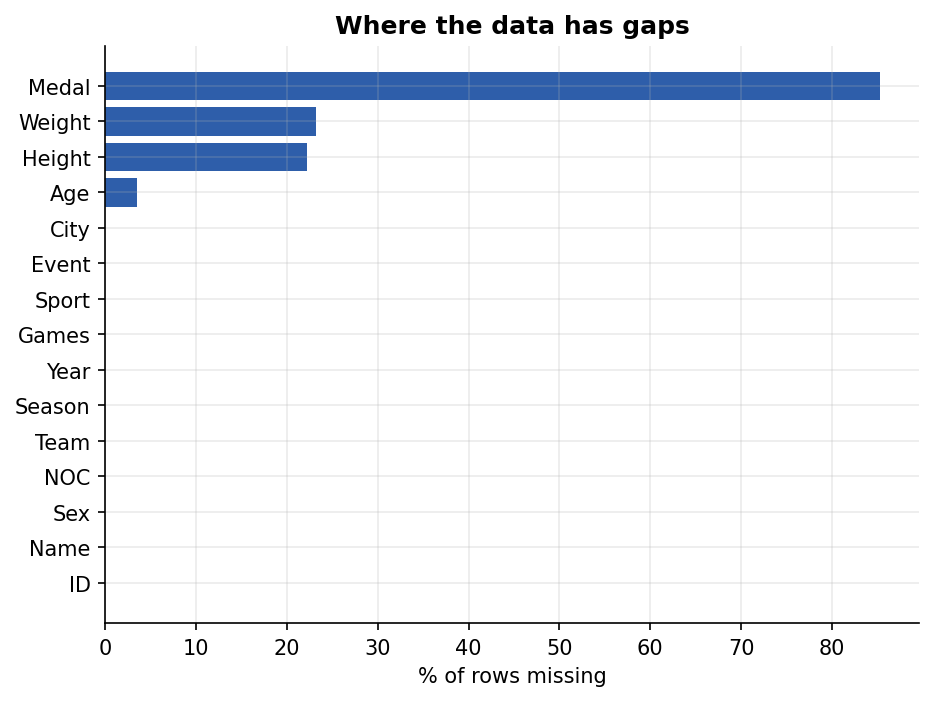


Summer Games: athletes, nations, events
  what: Number of athletes, competing nations and medal events at each edition.
  why : Growth in participation is the denominator behind every medal count: more events means more medals to win, so raw medal totals across eras are not directly comparable.


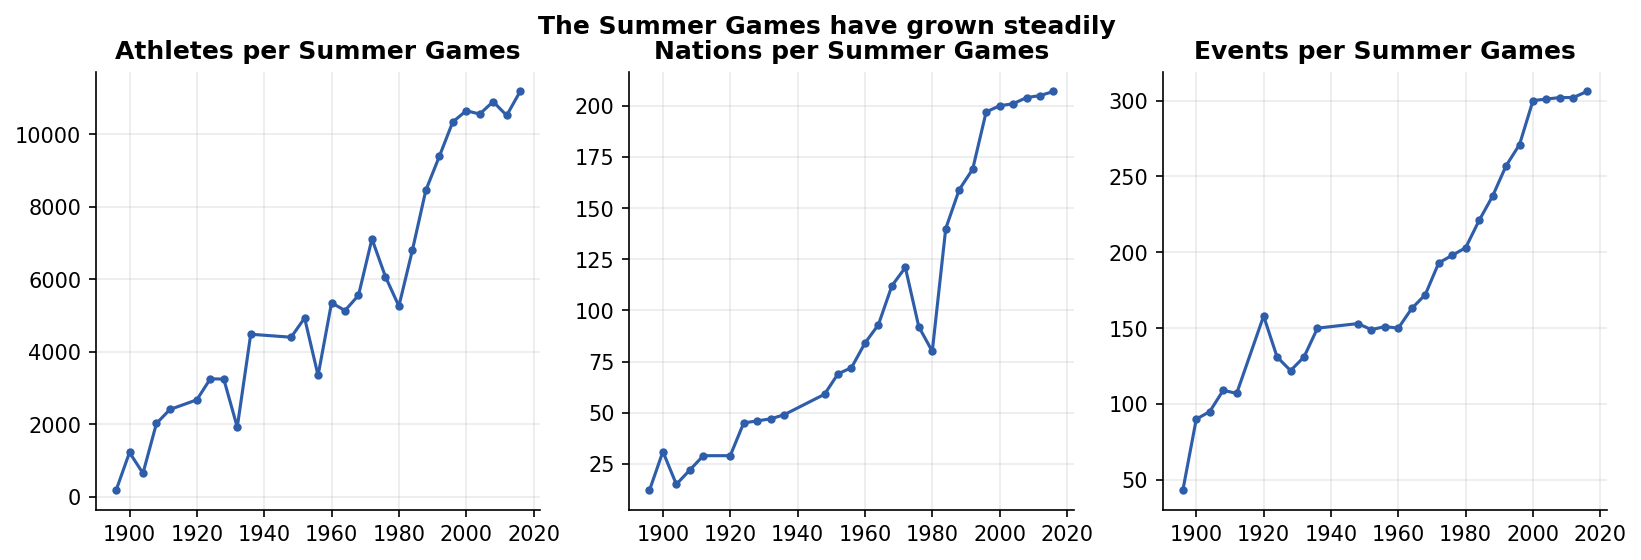


Share of women athletes over time
  what: Percentage of athletes who are women at each edition; dashed line is parity.
  why : Tracks progress toward gender parity and flags that pre-1990 data is heavily male, which affects any comparison of physique or age by sex.


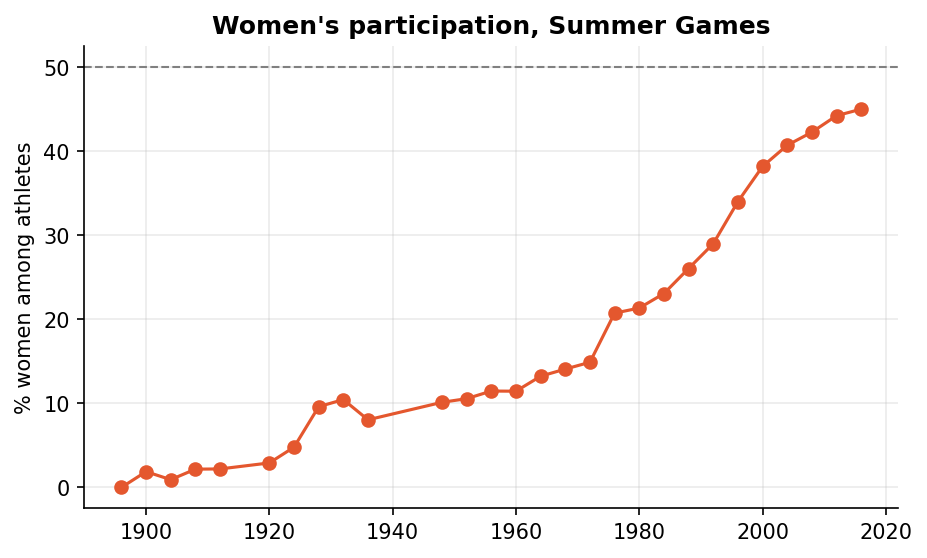


Medal trajectories of leading countries
  what: Medals won per edition by the all-time top countries; team events are counted once.
  why : Shows dynasties, boycotts (1980/1984), state dissolution and host bumps - context any forecast or ranking must respect.


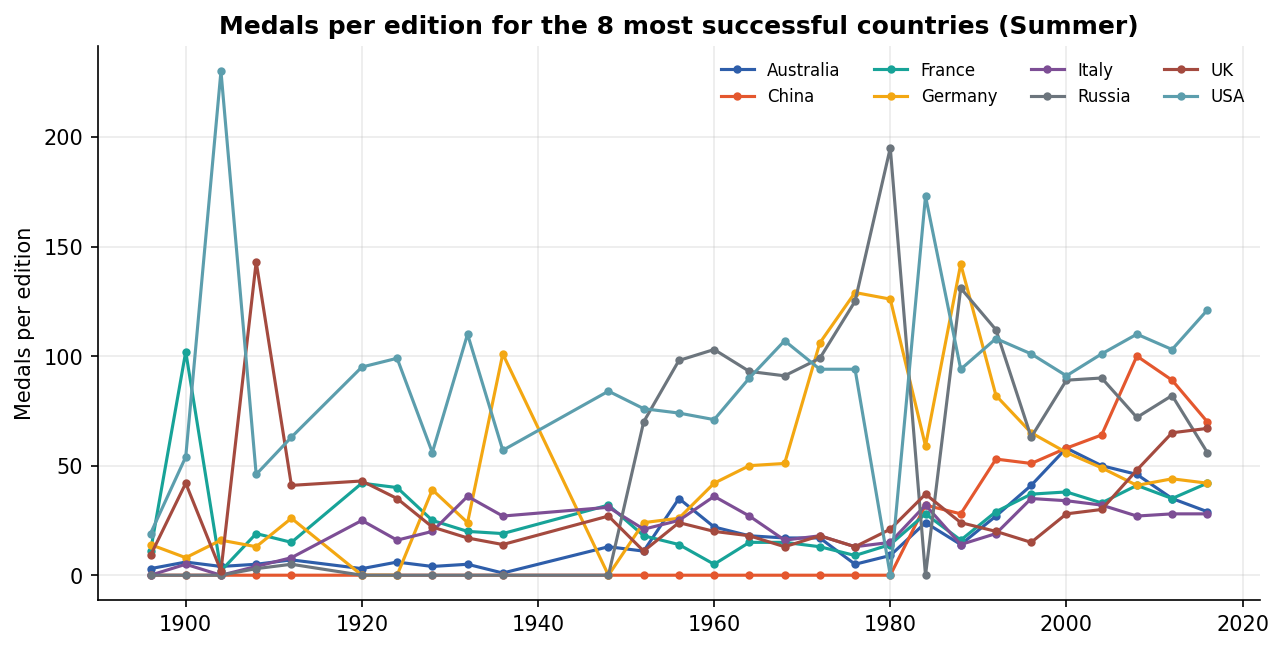


Age by sport
  what: Median, quartiles and range of athlete age in the most-contested sports.
  why : Motivates the ANOVA / Kruskal-Wallis test: sports clearly differ in typical age, so 'age' is only meaningful relative to the sport.


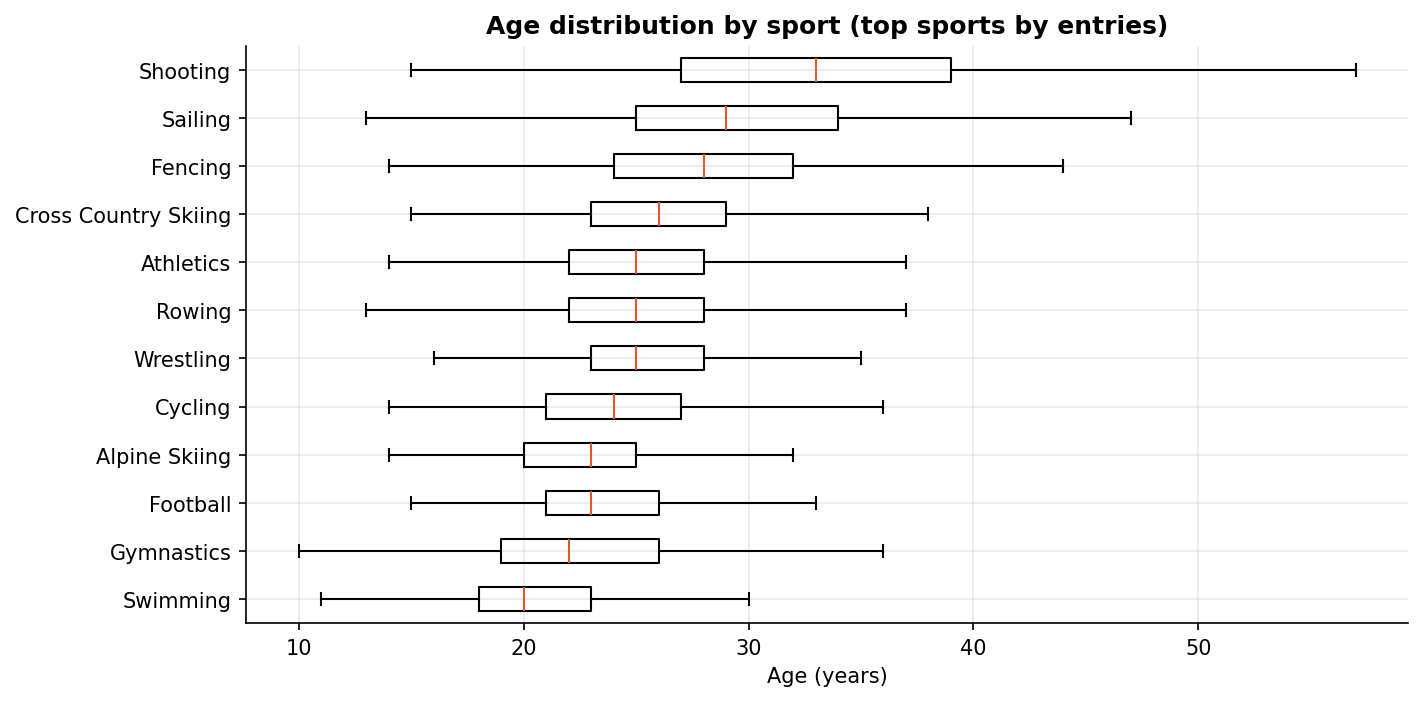


Physique of medallists vs the rest
  what: Density of height and weight for athletes who did and did not win a medal.
  why : Medallists are slightly taller/heavier on average, but the clouds overlap heavily: physique alone cannot predict medals.


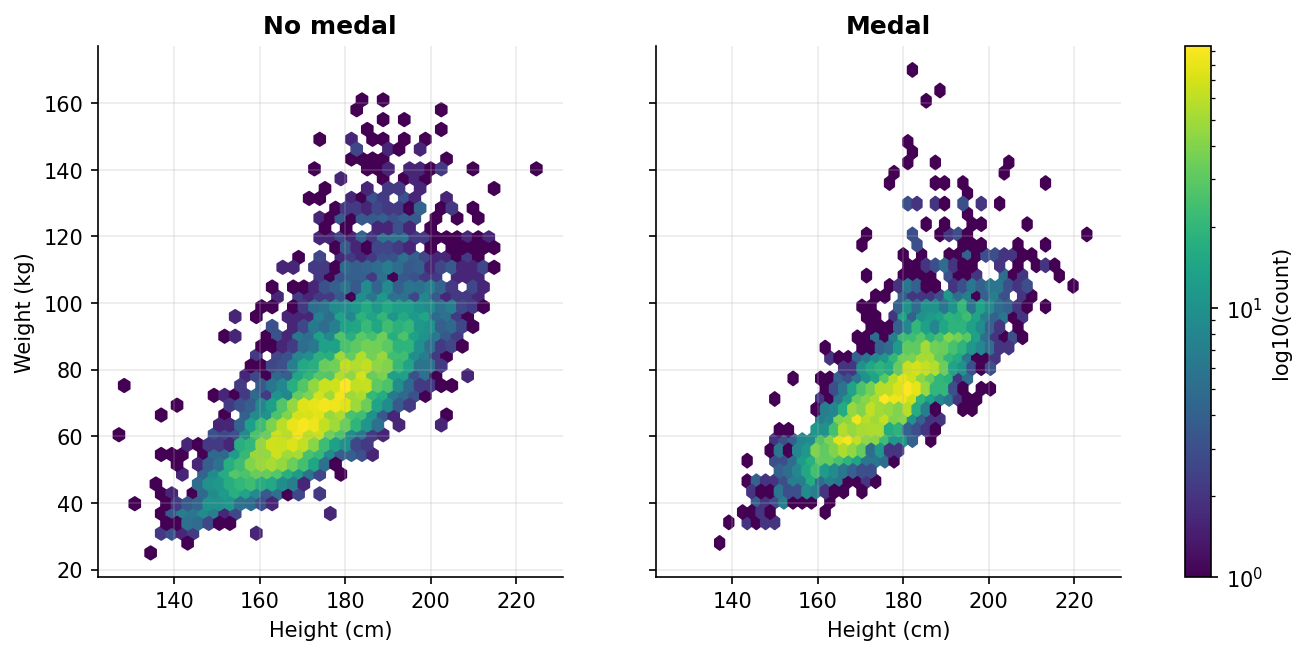


Medal rate with confidence intervals
  what: Medals per 100 athlete-event entries for the best countries, with 95% Wilson intervals.
  why : Countries with few entries have wide intervals; overlapping intervals mean the ranking between those countries is not statistically supported.


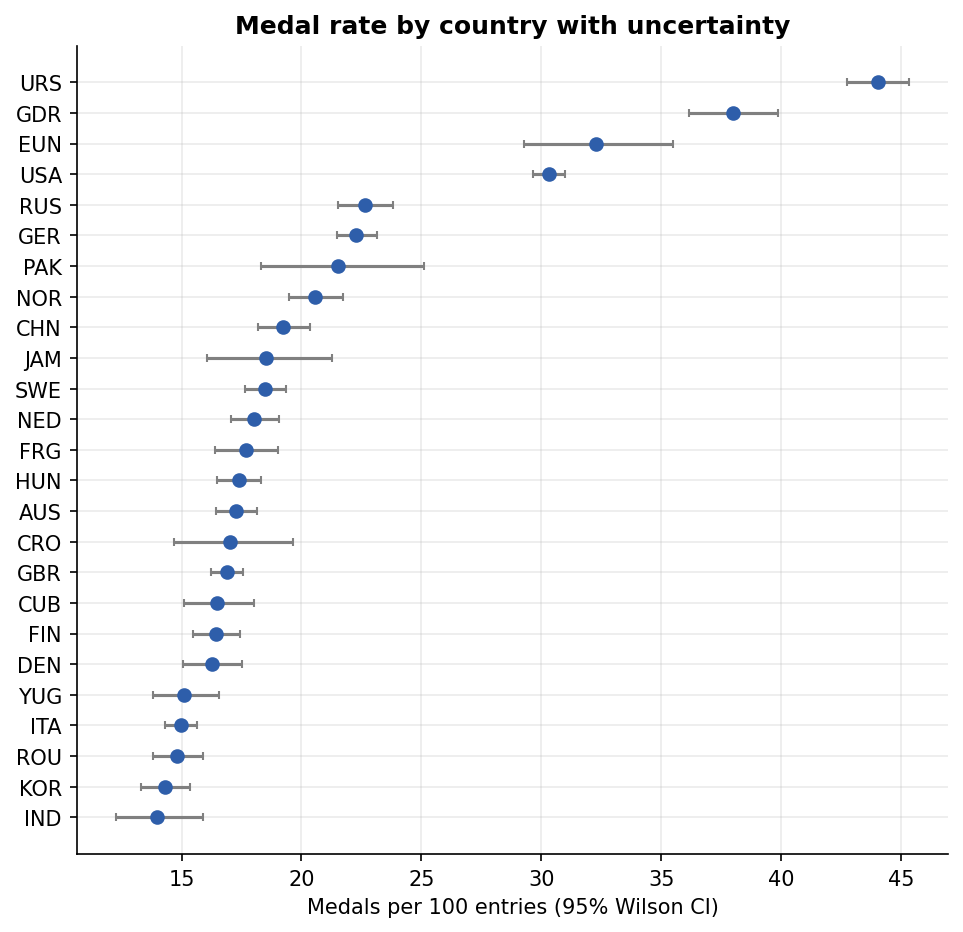


Host-nation advantage
  what: For every host country, share of medals at its home Games (red) vs its other Games (grey).
  why : A consistent shift right supports a real home advantage, which is why 'is_host' is a model and forecast feature.


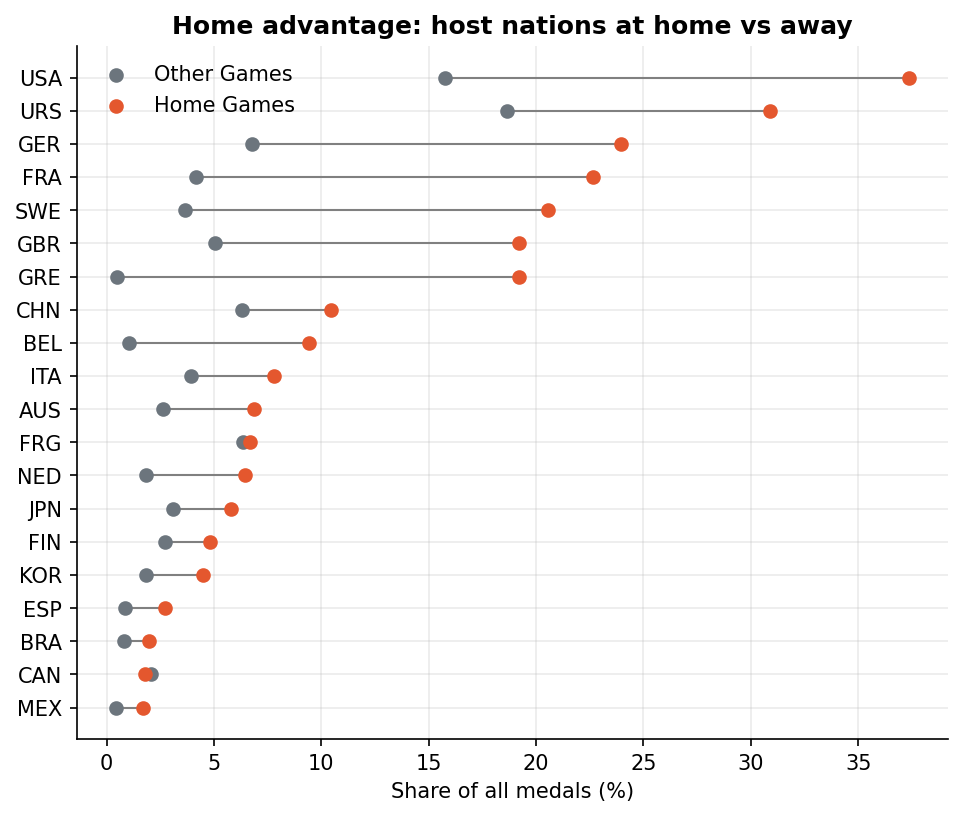


Correlation heatmap
  what: Rank correlation between age, body measures, year and medal outcome.
  why : Height, weight and BMI are strongly inter-correlated (redundant), while correlation with winning a medal is weak - a signal the problem needs context features such as country history.


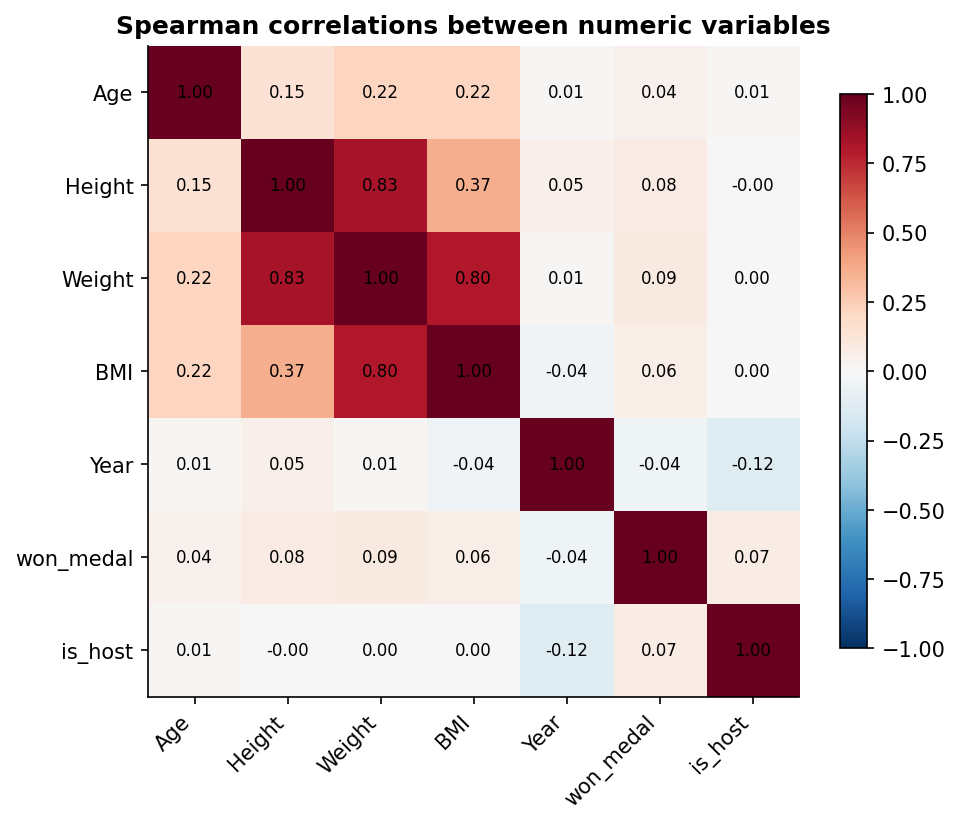


Which combinations drive the association
  what: Standardised residuals of the chi-square test: red = more entries than independence predicts, blue = fewer.
  why : A significant chi-square only says 'associated'; the residuals show where (e.g. which sports are male- or female-dominated).


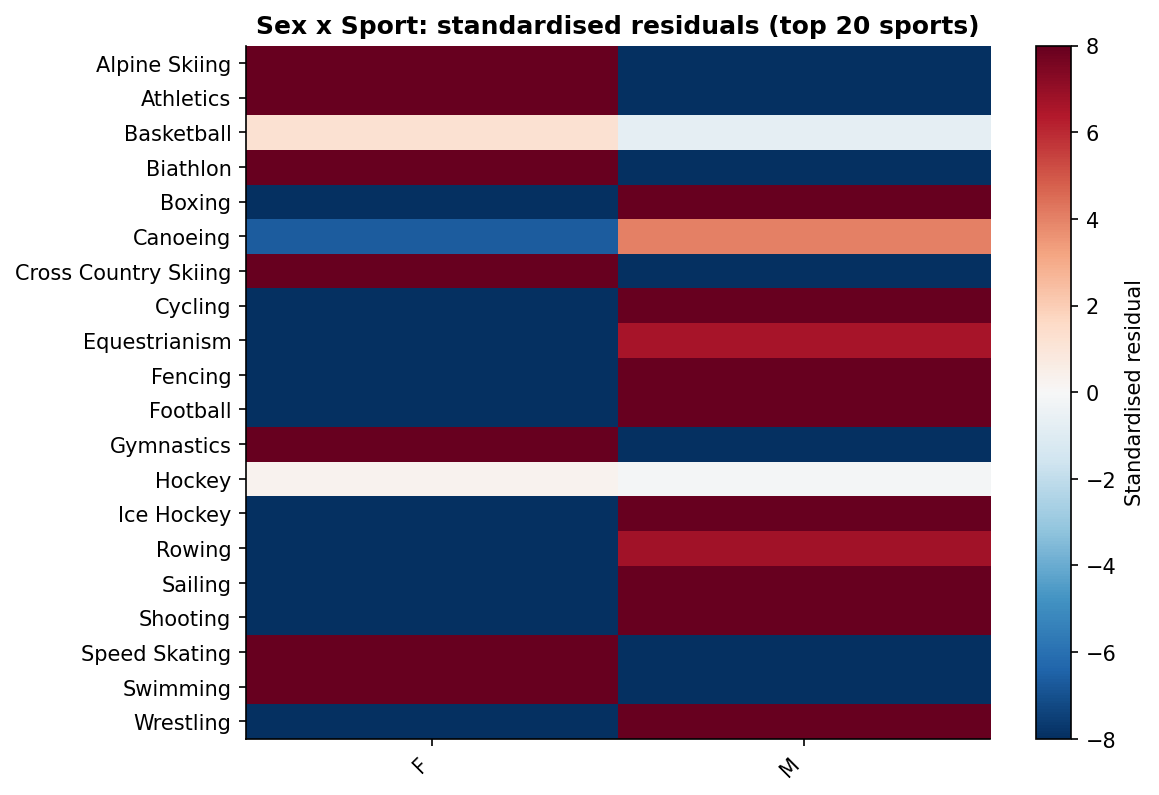


Participation vs medals
  what: Each dot is one country at one Games.
  why : Medals rise with delegation size, but with large scatter: the many dots at the bottom are big delegations that won nothing.


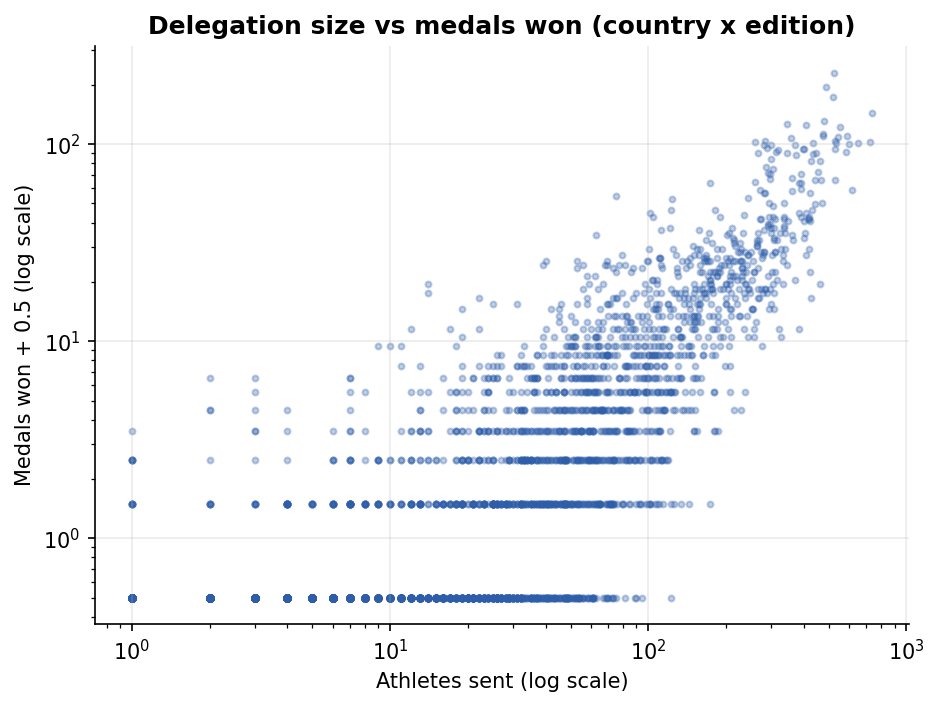


Medal forecast with uncertainty
  what: History of medals per edition (blue) and the forecast for the next Games with a prediction interval (red).
  why : Planning and benchmarking need a number *and* its uncertainty; the interval width comes from errors the model actually made when forecasting past editions.


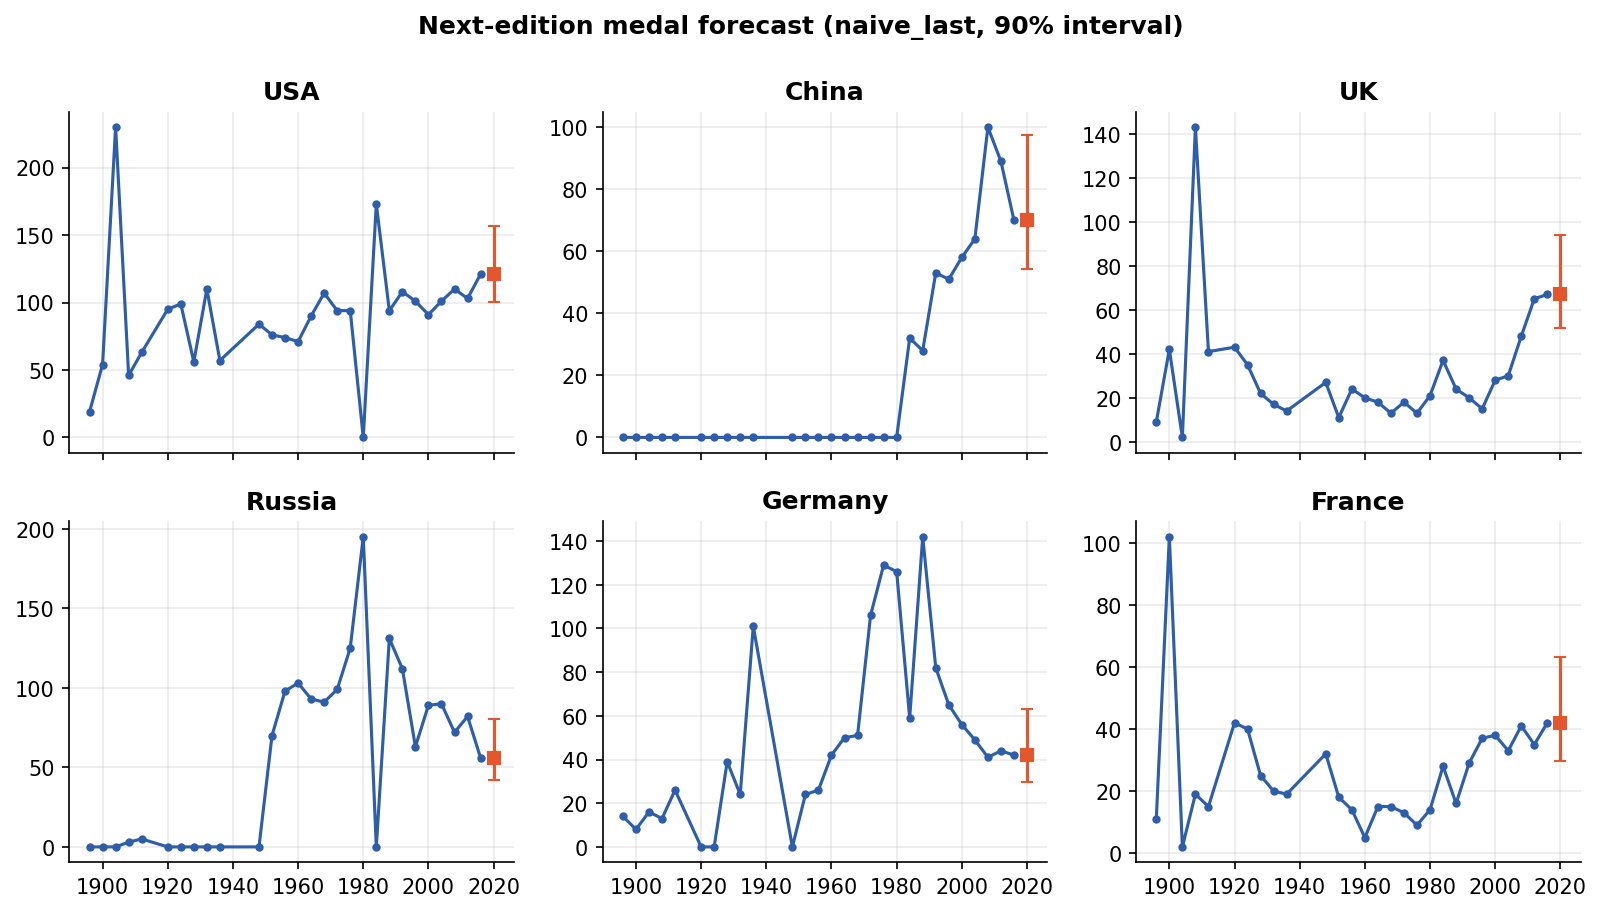


Which forecasting method wins?
  what: Average error of each method when predicting held-out editions; the red bar is the 'same as last time' baseline.
  why : A model that cannot beat the naive baseline adds complexity without value - this chart keeps every method honest.


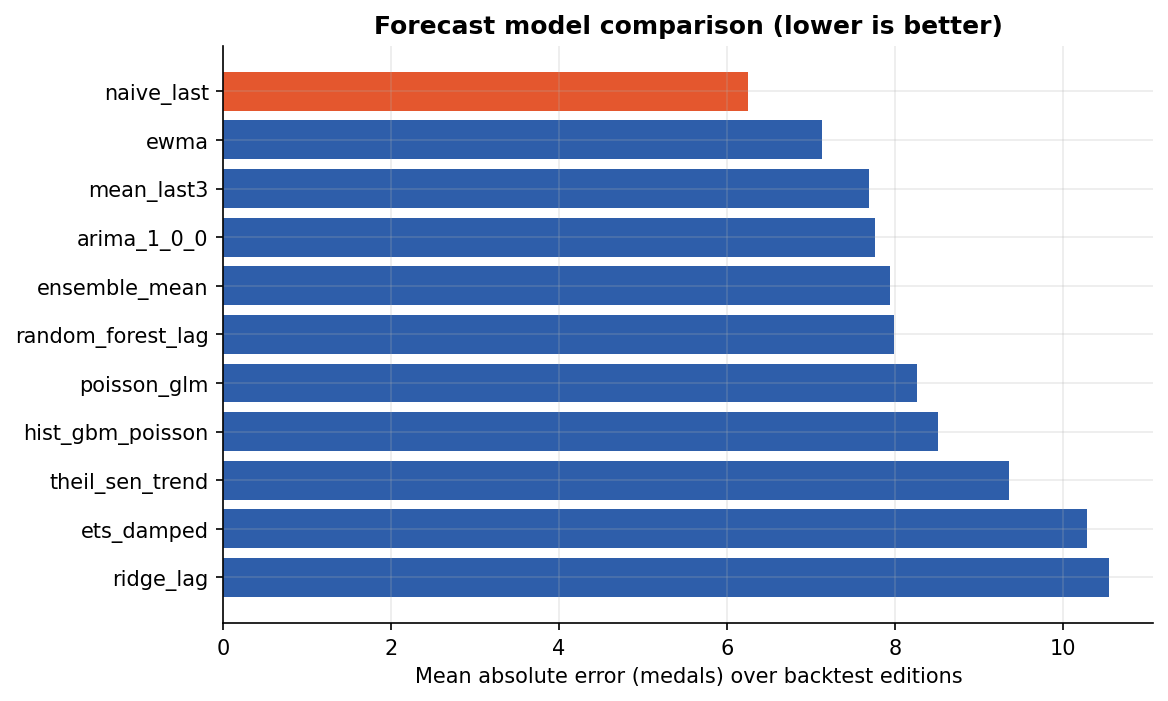


Model comparison
  what: PR-AUC, ROC-AUC and F1 for every candidate model on held-out validation data.
  why : Models are judged on PR-AUC (robust to the ~15% positive rate) rather than accuracy; the dashed line is what a model with no skill would score.


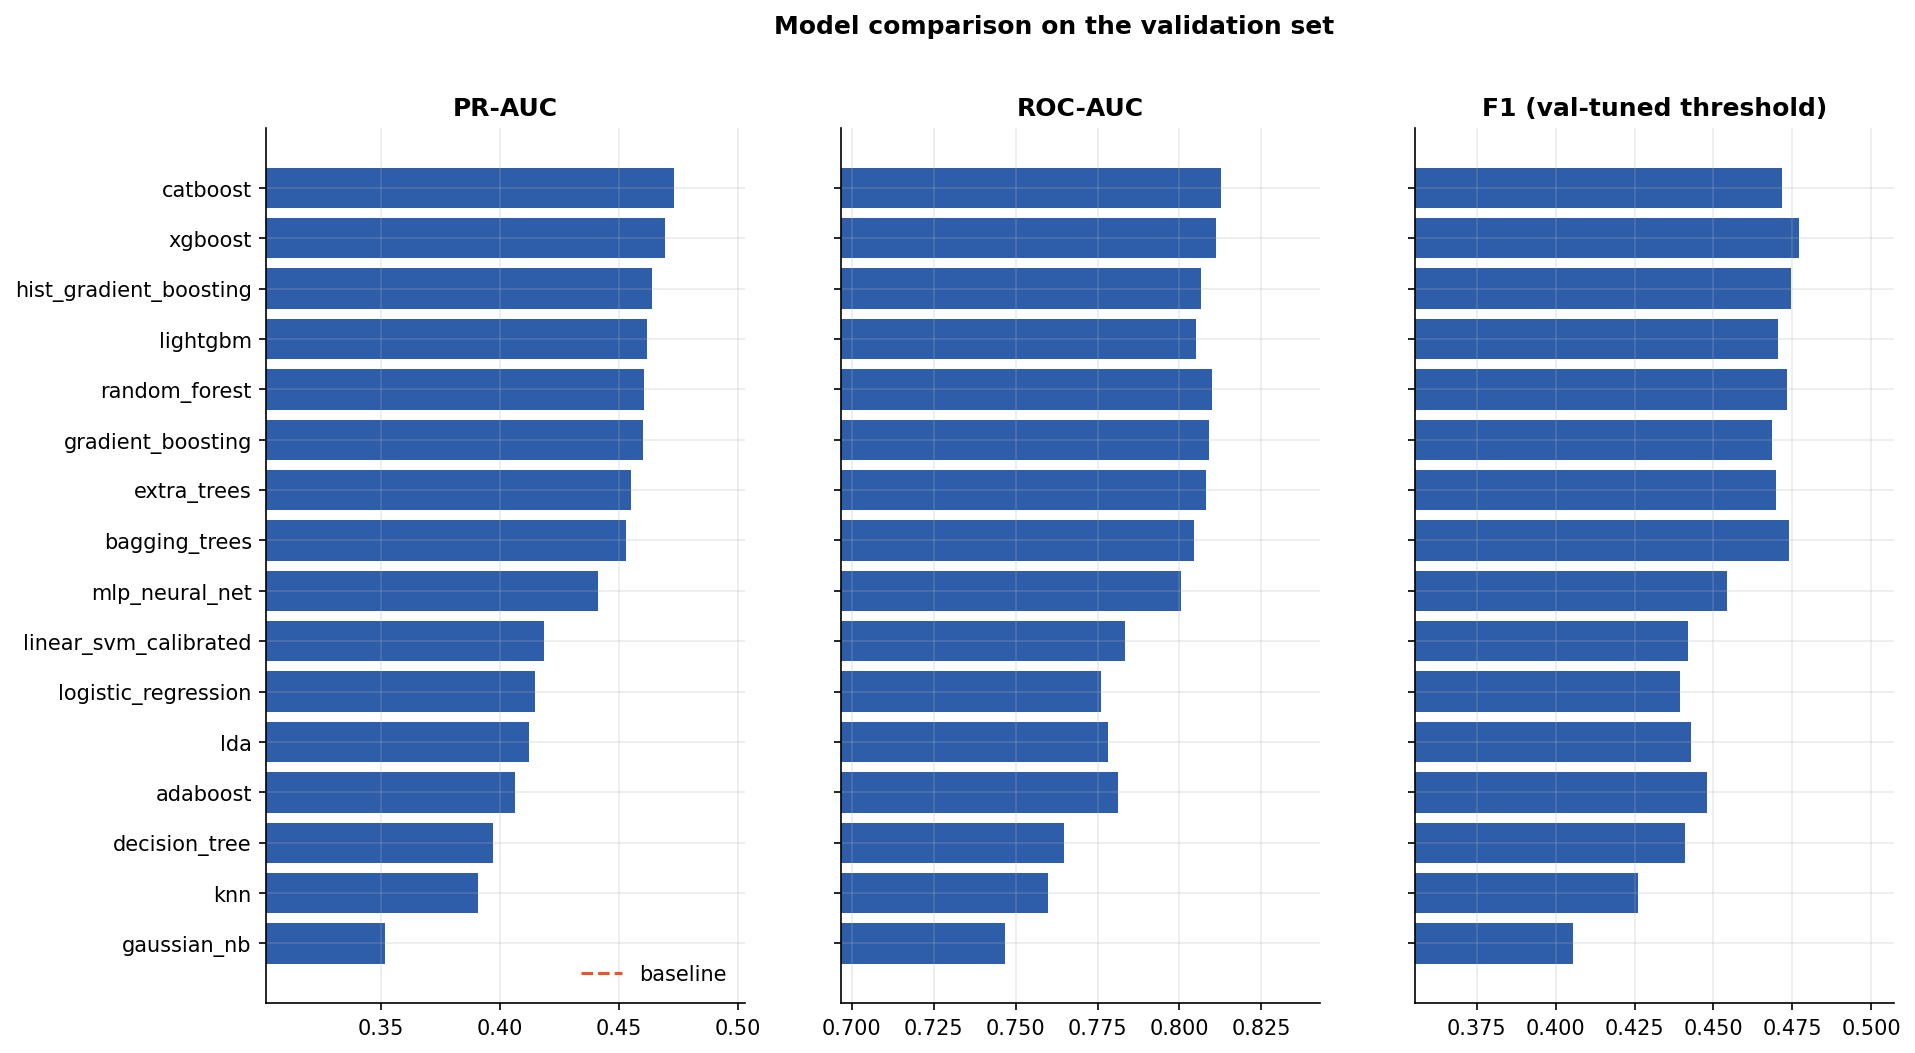


Precision-recall and ROC curves (top models)
  what: Trade-off between catching medallists (recall) and being right when flagging one (precision).
  why : On imbalanced data the PR curve exposes weaknesses ROC hides; the grey dashed PR line is the no-skill level.


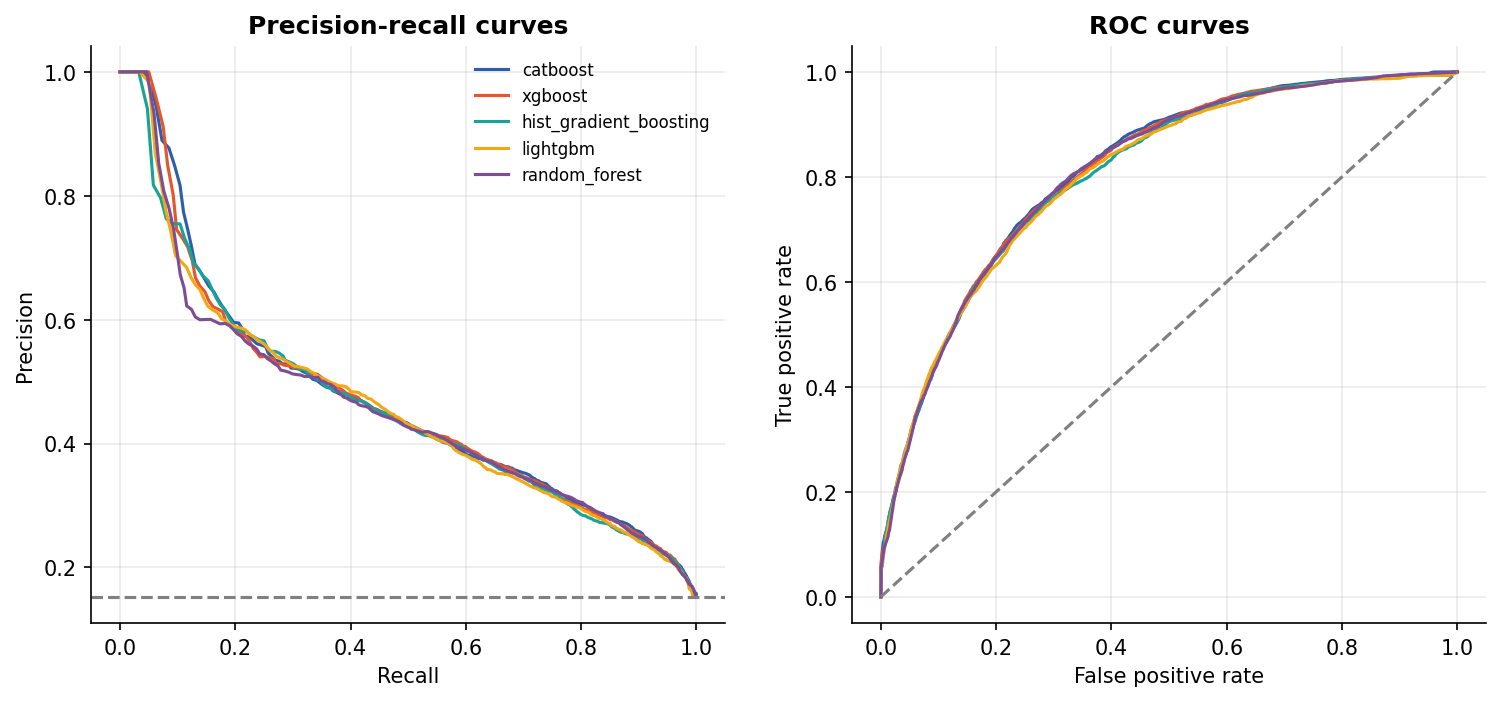


Calibration (are the probabilities trustworthy?)
  what: Predicted probability vs the medal rate actually observed, before and after calibration.
  why : If the model says 30% the medal rate should be ~30%; only then can the probabilities be used for planning and risk scoring, not just ranking.


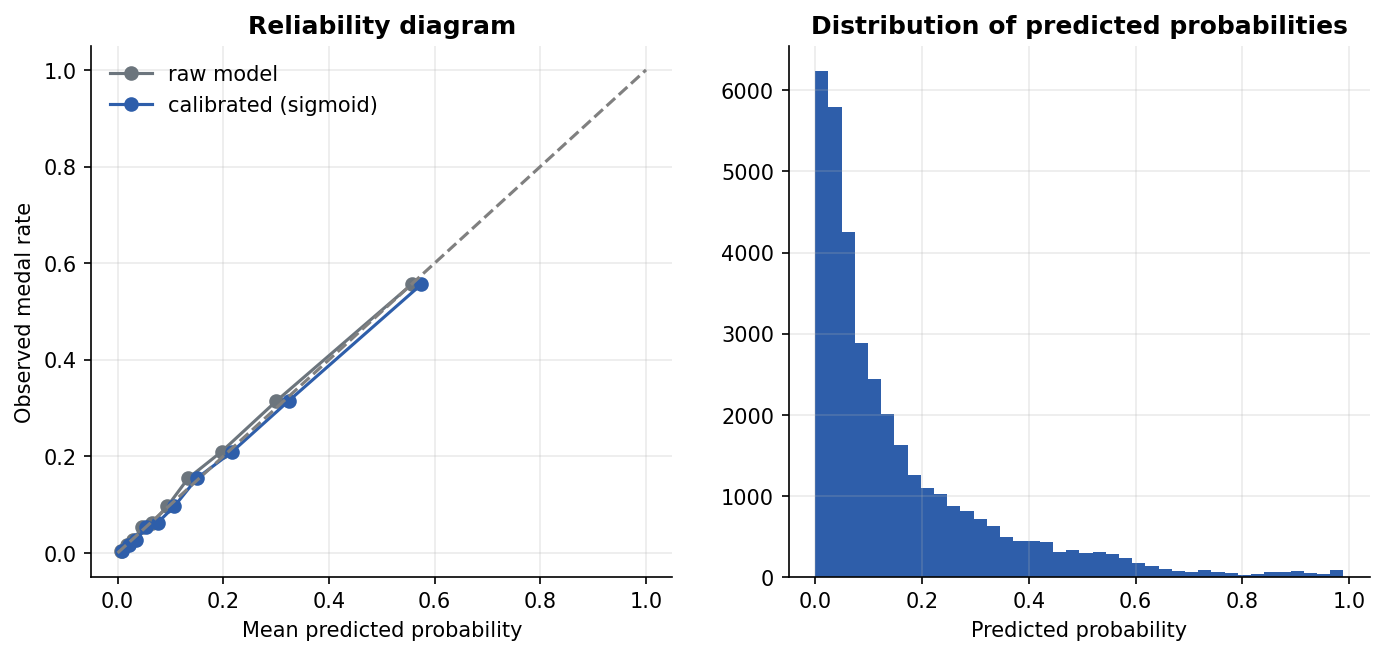


Confusion matrix on the test set
  what: Counts of correct and wrong calls at the chosen decision threshold.
  why : Shows the two kinds of mistake separately: false alarms (top right) vs missed medallists (bottom left).


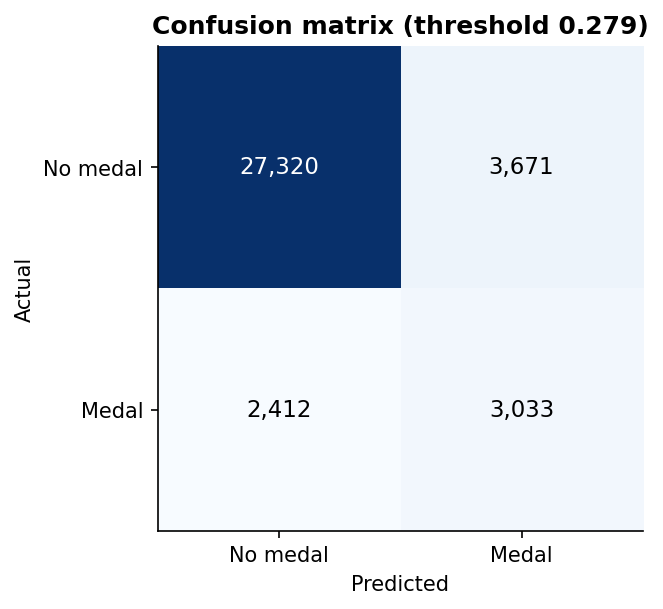


Choosing the decision threshold
  what: Precision, recall and F1 as the cut-off moves; the dashed line is the value picked on validation data.
  why : A fixed 0.5 cut-off ignores class imbalance and the different costs of false alarms and misses; this makes the trade-off explicit and tunable.


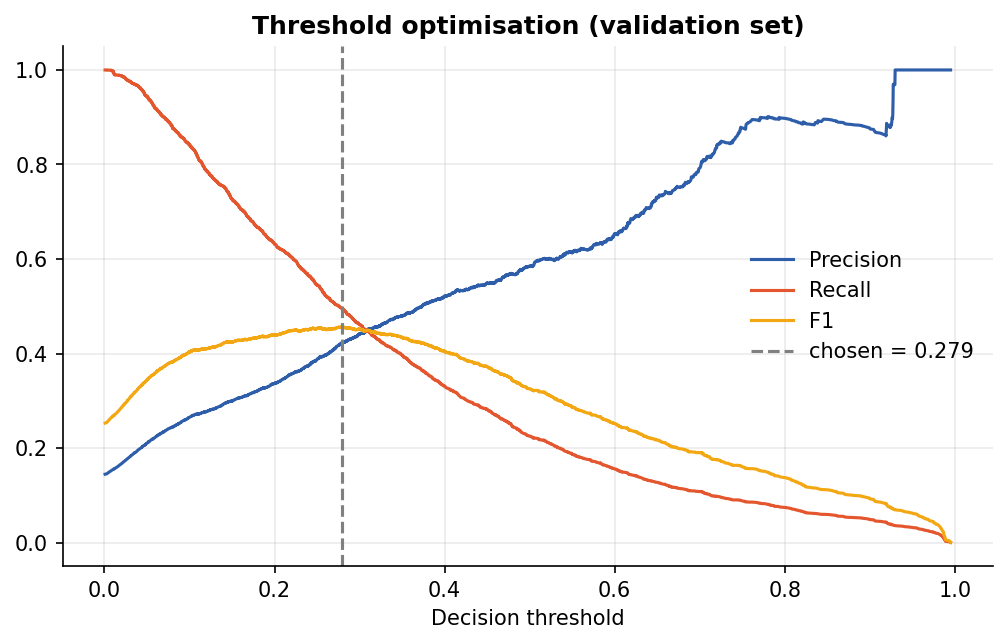


What drives the predictions
  what: How much model quality falls when each input is randomly shuffled.
  why : Confirms the model relies on sensible signals (country/sport history, event size) and flags suspicious dependence on identifiers or leakage-prone fields.


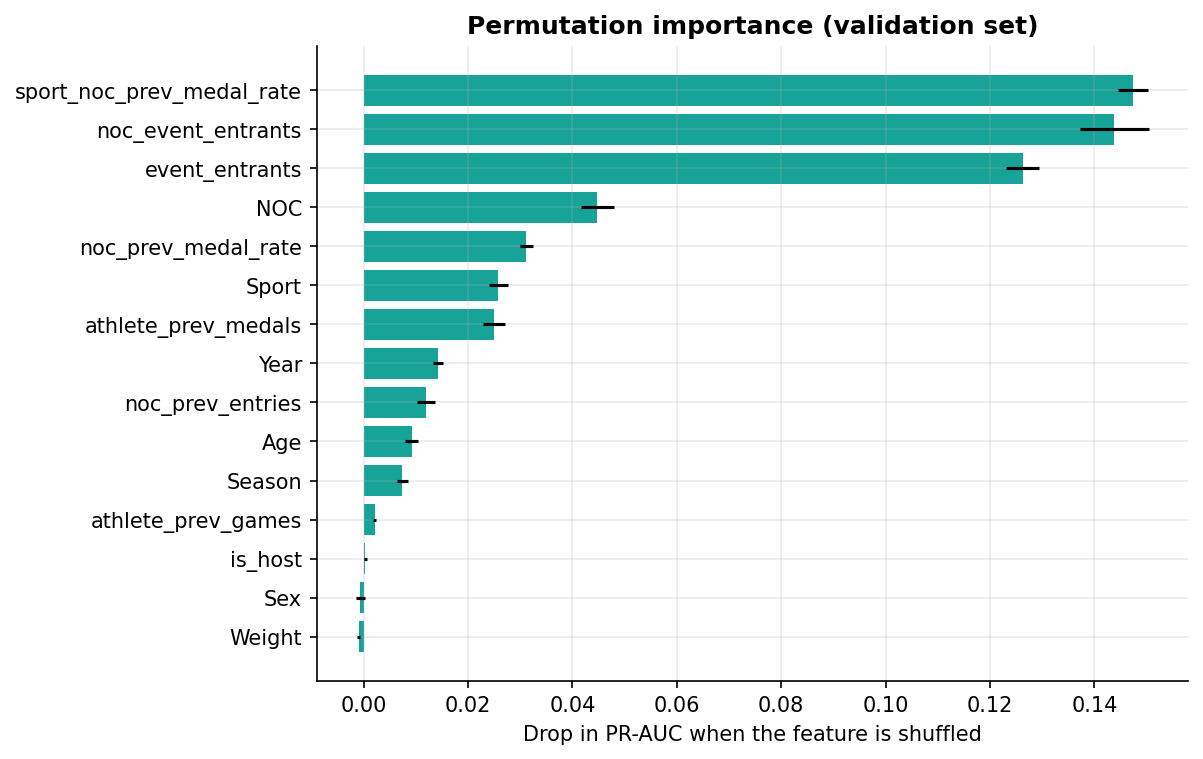


Does the model work equally well everywhere?
  what: Test PR-AUC for subgroups (sex, season, era, sport).
  why : A good overall score can hide a weak subgroup; reporting slices is the basic fairness and robustness check before deployment.


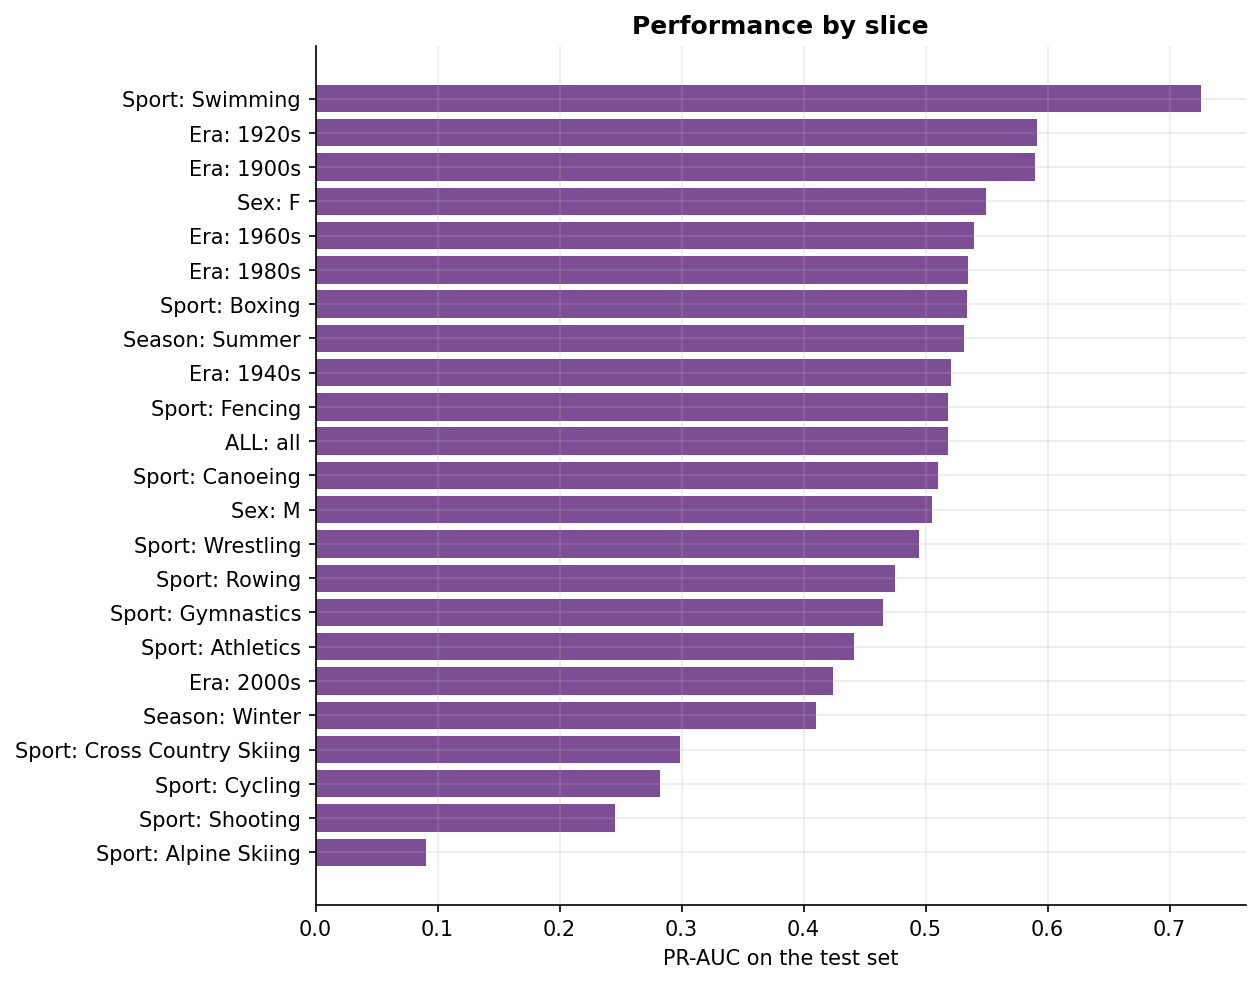

In [18]:
# All figures (each has a "what it shows / why it matters" caption in FIGURES.md)
from IPython.display import Image, display
idx = json.loads((pipe.paths.figures / "figure_index.json").read_text())
for name, meta in sorted(idx.items()):
    print(f"\n{meta['title']}\n  what: {meta['what_it_shows']}\n  why : {meta['why_it_matters']}")
    display(Image(str(pipe.paths.figures / meta["file"]), width=760))

## 9 · Dashboard (Gradio) — filters, country comparison, drill-downs, predictor with explanations, feedback, SQL console

In [19]:
from apps.dashboard.app import build_app
demo_app = build_app(str(ROOT))
demo_app.launch(share=True, debug=False)     # prints a public link valid while this session runs

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://97deb777a92d7308b6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10 · (Optional) FastAPI service inside Colab
Starts the REST API in the background and prints a link to the interactive docs (`/docs`).

In [20]:
import threading, time, uvicorn
from apps.api.main import app as api_app
cfg_srv = uvicorn.Config(api_app, host="0.0.0.0", port=8000, log_level="warning")
server = uvicorn.Server(cfg_srv)
threading.Thread(target=server.run, daemon=True).start(); time.sleep(3)
if IN_COLAB:
    from google.colab import output
    print("API docs:", output.eval_js("google.colab.kernel.proxyPort(8000)") + "docs")
import requests
print(requests.get("http://127.0.0.1:8000/health").json())
print(requests.post("http://127.0.0.1:8000/predict?explain=true", json={"Age": 24, "Height": 185, "Weight": 78, "Sex": "M", "NOC": "USA",
      "Sport": "Swimming", "Season": "Summer", "Year": 2016, "athlete_prev_medals": 3}).json())

ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use


API docs: https://8000-gpu-t4-s-euw4c0-1rcyf8z3elql5-c.europe-west4.prod.r.colab.devdocs
{'status': 'ok', 'model_version': 'v20261102-0431-7a31d23b', 'uptime_s': 27.8}
{'prediction_id': '309705df2c94', 'probability': 0.77951, 'predicted_medal': True, 'threshold': 0.278992506532482, 'model_version': 'v20261102-0431-7a31d23b', 'explanation': [{'feature': 'sport_noc_prev_medal_rate', 'value': 0.6568, 'typical_value': 0.1467, 'effect_on_probability': 0.49153232701681954}, {'feature': 'athlete_prev_medals', 'value': 3.0, 'typical_value': 0.0, 'effect_on_probability': 0.2036978192584079}, {'feature': 'NOC', 'value': 'USA', 'typical_value': 'UNKNOWN', 'effect_on_probability': 0.1746309516562936}, {'feature': 'noc_prev_medal_rate', 'value': 0.3376, 'typical_value': 0.1467, 'effect_on_probability': -0.12434404508516794}, {'feature': 'event_entrants', 'value': 20.0, 'typical_value': 60.0, 'effect_on_probability': 0.12053273461610747}, {'feature': 'noc_prev_entries', 'value': 14734.0, 'typical_va

## 11 · Human feedback → retraining
Predictions made in the dashboard/API are logged; confirm outcomes there (or in `feedback/feedback.jsonl`), then run this cell. The challenger replaces the champion only if it is not worse on the same untouched test split.

In [21]:
from olympics.ml.retrain import retrain_with_feedback
from olympics.checkpoint import fingerprint
ml = pipe.ml_frame()
print(retrain_with_feedback(cfg, pipe.paths, ml, pipe.tracker, fingerprint(len(ml), cfg["data"]["source"], USE_DEMO_DATA), force=False))

{'status': 'skipped', 'reason': 'only 0 labelled feedback rows (< 200)'}


## 12 · Package everything for download
Everything is already in Drive; this makes a single zip of the reports/models for convenience.

In [22]:
out_zip = BASE / "olympics_results"
shutil.make_archive(str(out_zip), "zip", root_dir=ROOT, base_dir="reports")
print("Reports zip:", str(out_zip) + ".zip")
for name in ("models",):
    shutil.make_archive(str(BASE / f"olympics_{name}"), "zip", root_dir=ROOT, base_dir=name)
print("Models zip :", str(BASE / "olympics_models.zip"))
if IN_COLAB:
    from google.colab import files
    files.download(str(out_zip) + ".zip")

Reports zip: /content/drive/MyDrive/Olympics-Analytics/olympics_results.zip
Models zip : /content/drive/MyDrive/Olympics-Analytics/olympics_models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Troubleshooting
* **Runtime disconnected** → reconnect, *Runtime → Run all*. Finished stages print `already complete - skipping`.
* **Kaggle 403 / not found** → accept the dataset's terms on its Kaggle page, then re-run cell 7a with `FORCE_STAGES = "ingest"`.
* **Switching to the `olympedia` dataset** → run `!python -m olympics.cli inspect-source --root $OLYMPICS_ROOT --set data.source=olympedia` and check the printed file/column names match the adapter (see README).
* **Out of memory** → set `PROFILE = "fast"` or add `ml.compare_max_rows=80000` to `overrides` in cell 6.